# 07. Feature Engineering & Dataset Preparation for Predictive Modeling

Notebook ini merealisasikan pipeline **Feature Engineering** dan **Penyelarasan Data Latih** berdasarkan hierarki data iklim terpadu `dataset/climate_dataset.zarr`.

Sesuai instruksi dan pedoman metodologi pada [README.md](../README.md):
1. **Reduksi Spasial Grid SST**: Menggunakan pembobotan cosinus lintang (*latitude-weighted mean*) untuk wilayah Niño 3.4 dan wilayah perairan Indonesia.
2. **Gradien Spasial**: Mengekstraksi kontras zonal SST Timur–Barat Pasifik ekuatorial untuk menangkap dinamika termoklin.
3. **Harmonisasi Multivariat**: Mengintegrasikan indeks atmosfer (SOI), osilasi laut (ONI, DMI), gelombang panas laut (MHW), dan curah hujan regional (Malaysia & Hawaii).
4. **Siklus Musiman (*Phase Locking*)**: Encoding kalender siklis ($\sin, \cos$) untuk memodelkan penguncian fase musiman ENSO (*Spring Predictability Barrier*).
5. **Fitur Lag Waktu & Rolling Windows**: Memodelkan inersia dinamika laut-atmosfer dengan lag ($t-1, t-2, t-3, t-6, t-12$) serta rata-rata dan volatilitas bergerak 3 dan 6 bulan.
6. **Perumusan Target Multi-Lead ($t+1, t+3, t+6$)**: Target kontinu (regresi anomali) dan target diskret (klasifikasi 3-fase ENSO: El Niño, Netral, La Niña).
7. **Pemisahan Kronologis Bebas Leakage**: Skema *walk-forward split* berbasis urutan waktu (Train 2015–2021, Val 2022–2023, Test 2024–2025) dengan *StandardScaler* yang di-fit hanya pada subset latih.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Set aesthetic visual
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["figure.dpi"] = 120

PROJECT_ROOT = Path("..").resolve() if Path(".").resolve().name == "notebook" else Path(".").resolve()
ZARR_STORE = PROJECT_ROOT / "dataset" / "climate_dataset.zarr"
FIGURES_DIR = PROJECT_ROOT / "notebook" / "reports" / "figures"
DATASET_DIR = PROJECT_ROOT / "dataset"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root : {PROJECT_ROOT}")
print(f"Zarr store   : {ZARR_STORE}")
print(f"Figures dir  : {FIGURES_DIR}")


Project root : C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model
Zarr store   : C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\dataset\climate_dataset.zarr
Figures dir  : C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures


## 1. Ekstraksi Multivariat & Pembobotan Spasial Grid SST

Berdasarkan [README.md](../README.md) (poin 3 pra-pemrosesan):
> *"Bila merata-ratakan grid, gunakan pembobotan luas (misalnya bobot proporsional terhadap cosinus lintang) dan dokumentasikan penanganan daratan/nilai hilang."*

Fungsi di bawah ini menerapkan bobot $w_i = \cos(	ext{latitude}_i)$ pada grid SST 2D/3D (NOAA OISST v2.1) sebelum diagregasikan ke deret waktu 1D.

In [2]:
def get_weighted_sst(ds: xr.Dataset) -> xr.DataArray:
    """Menghitung rata-rata spasial SST tertimbang cosinus lintang."""
    lat = ds["lat"]
    weights = np.cos(np.deg2rad(lat))
    weights.name = "weights"
    return ds["sst"].weighted(weights).mean(dim=["lat", "lon", "zlev"])

# 1. Load Indeks Iklim 1D
ds_oni = xr.open_zarr(ZARR_STORE, group="data_oni/oni", consolidated=False)
ds_soi = xr.open_zarr(ZARR_STORE, group="data_soi/soi", consolidated=False)
ds_dmi = xr.open_zarr(ZARR_STORE, group="data_dmi/dmi", consolidated=False)
ds_mhw = xr.open_zarr(ZARR_STORE, group="data_mhw/mhw_labels", consolidated=False)
ds_rain_my = xr.open_zarr(ZARR_STORE, group="data_rainfall_monthly/malaysia", consolidated=False)
ds_rain_hw = xr.open_zarr(ZARR_STORE, group="data_rainfall_monthly/hawaii", consolidated=False)

# 2. Load Grid Spasial SST
ds_sst_nino = xr.open_zarr(ZARR_STORE, group="sst_5_wilayah/pasifik_nino34", consolidated=False)
ds_sst_kari = xr.open_zarr(ZARR_STORE, group="sst_5_wilayah/selat_karimata", consolidated=False)
ds_sst_maka = xr.open_zarr(ZARR_STORE, group="sst_5_wilayah/selat_makassar", consolidated=False)

# Hitung weighted spatial mean SST
sst_nino_w = get_weighted_sst(ds_sst_nino)
sst_kari_w = get_weighted_sst(ds_sst_kari)
sst_maka_w = get_weighted_sst(ds_sst_maka)

# Hitung Gradien Zonal SST Niño 3.4 (Timur vs Barat)
weights_nino = np.cos(np.deg2rad(ds_sst_nino["lat"]))
weights_nino.name = "weights"
sst_east = ds_sst_nino["sst"].sel(lon=slice(-145, -119.875)).weighted(weights_nino).mean(dim=["lat", "lon", "zlev"])
sst_west = ds_sst_nino["sst"].sel(lon=slice(-169.875, -145)).weighted(weights_nino).mean(dim=["lat", "lon", "zlev"])
zonal_grad = sst_east - sst_west

# Susun DataFrame dasar bulanan
df_base = pd.DataFrame(index=pd.DatetimeIndex(ds_oni["time"].values, name="time"))

# Indeks Utama
df_base["oni_anom"] = ds_oni["ANOM"].values
df_base["oni_total"] = ds_oni["TOTAL"].values
df_base["soi"] = ds_soi["SOI"].values
df_base["dmi"] = ds_dmi["DMI"].values

# SST Tertimbang
df_base["sst_nino34"] = sst_nino_w.values
df_base["sst_nino34_zonal_grad"] = zonal_grad.values
df_base["sst_karimata"] = sst_kari_w.values
df_base["sst_makassar"] = sst_maka_w.values
df_base["sst_jawa"] = ds_mhw["Selatan_Jawa_sst"].values
df_base["sst_maluku"] = ds_mhw["Maluku_Utara_Papua_sst"].values

# MHW Event Status (Binary)
df_base["mhw_nino34"] = ds_mhw["Pasifik_Nino34_is_mhw"].values.astype(int)
df_base["mhw_karimata"] = ds_mhw["Selat_Karimata_is_mhw"].values.astype(int)
df_base["mhw_makassar"] = ds_mhw["Selat_Makassar_is_mhw"].values.astype(int)
df_base["mhw_jawa"] = ds_mhw["Selatan_Jawa_is_mhw"].values.astype(int)
df_base["mhw_maluku"] = ds_mhw["Maluku_Utara_Papua_is_mhw"].values.astype(int)

# Curah Hujan
df_base["rain_malaysia"] = ds_rain_my["rfh"].values
df_base["rain_hawaii"] = ds_rain_hw["rain_mean_daily_mm"].values

print(f"Data dasar berhasil disusun: {df_base.shape[0]} baris x {df_base.shape[1]} kolom.")
df_base.head()


Data dasar berhasil disusun: 132 baris x 17 kolom.


,oni_anom,oni_total,soi,dmi,sst_nino34,sst_nino34_zonal_grad,sst_karimata,sst_makassar,sst_jawa,sst_maluku,mhw_nino34,mhw_karimata,mhw_makassar,mhw_jawa,mhw_maluku,rain_malaysia,rain_hawaii
time,,,,,,,,,,,,,,,,,
2015-01-01,0.73,27.28,-1.4,-0.100,27.013042,-1.199617,28.265079,29.330164,28.909796,29.271365,0,0,0,0,0,80.683169,3.141978
2015-02-01,0.65,27.43,0.4,-0.345,27.430071,-0.857502,27.663864,29.097498,29.224506,28.918380,0,0,0,0,0,34.569858,3.167782
2015-03-01,0.72,27.95,-1.2,-0.241,27.632812,-0.917631,28.495840,29.399933,29.414530,28.651275,0,0,0,0,0,44.102277,5.495336
2015-04-01,0.86,28.49,-0.1,-0.008,28.619818,-0.525032,29.409231,29.821741,29.678258,29.437296,0,0,0,0,0,77.051495,6.312998
2015-05-01,1.04,28.83,-1.2,0.240,28.709501,-0.840855,29.893549,29.890209,29.027032,29.592382,0,0,0,0,0,71.056933,5.407186


## 2. Rekayasa Fitur Musiman (*Cyclical Encoding*)

ENSO memiliki keterikatan musiman yang kuat (*phase-locking*):
- Anomali El Niño dan La Niña biasanya mencapai puncak kematangan pada akhir tahun (November–Januari).
- Transisi fase dan ketidakpastian terbesar terjadi pada musim semi (*Spring Predictability Barrier*, Maret–Mei).

Pengkodean bulan siklis menggunakan fungsi trigonometri menjamin kontinuitas antara bulan Desember (12) dan Januari (1):
$$\text{sin\_month} = \sin\left(\frac{2\pi \cdot \text{month}}{12}\right), \quad \text{cos\_month} = \cos\left(\frac{2\pi \cdot \text{month}}{12}\right)$$

In [ ]:
months = df_base.index.month
df_features = df_base.copy()

df_features["month_sin"] = np.sin(2 * np.pi * months / 12)
df_features["month_cos"] = np.cos(2 * np.pi * months / 12)

# Rasio SOI terhadap ONI (Kopling Atmosfer-Laut)
# Normalisasi tanda: saat El Nino, ONI > 0 dan SOI < 0, sehingga -SOI sejalan dengan ONI
df_features["enso_coupling_index"] = df_features["oni_anom"] - df_features["soi"]

print("Fitur musiman & kopling atmosfer berhasil ditambahkan.")

Fitur musiman & kopling atmosfer berhasil ditambahkan.


## 3. Rekayasa Fitur Lag Waktu & Statistik Bergerak (*Rolling Windows*)

Berdasarkan [README.md](../README.md) (Tabel Alur Blok 5):
> *"Fitur dapat mencakup lag RONI/SST, SOI, DMI, monsun, angin, dan panas bawah permukaan."*

Variabel driver iklim utama diberikan fitur jeda waktu historis ($t-1, t-2, t-3, t-6, t-12$) serta statistik jendela bergerak:
- **Rolling Mean (3 & 6 Bulan)**: Menangkap kecenderungan tren akumulatif (misal: syarat operasional NOAA butuh anomali bertahan 5 musim berturut-turut).
- **Rolling Std (3 Bulan)**: Menangkap volatilitas dan ketidakstabilan atmosfer-laut.

In [4]:
lag_vars = ["oni_anom", "soi", "dmi", "sst_nino34", "sst_nino34_zonal_grad", "sst_makassar", "rain_malaysia"]
lags = [1, 2, 3, 6, 12]

# Buat lag features
for col in lag_vars:
    for lag in lags:
        df_features[f"{col}_lag{lag}"] = df_features[col].shift(lag)

# Buat rolling features (berbasis t-1 untuk mencegah data leakage target)
# Perhatikan: rolling diterapkan pada lag1 agar nilai saat t tidak bocor ke masa depan
for col in ["oni_anom", "soi", "dmi", "sst_nino34"]:
    df_features[f"{col}_roll3_mean"] = df_features[f"{col}_lag1"].rolling(3).mean()
    df_features[f"{col}_roll3_std"] = df_features[f"{col}_lag1"].rolling(3).std()
    df_features[f"{col}_roll6_mean"] = df_features[f"{col}_lag1"].rolling(6).mean()

print(f"Total fitur setelah lagging dan rolling: {df_features.shape[1]} kolom.")


Total fitur setelah lagging dan rolling: 67 kolom.


## 4. Perumusan Target Prediksi Multi-Lead ($t+1, t+3, t+6$)

Berdasarkan [README.md](../README.md) (Metode Pertanyaan A):
> *"Gunakan target kontinu dahulu: prediksi RONI/Niño 3.4 untuk beberapa lead bulanan yang realistis, lalu konversi prakiraan kontinu/ensemble menjadi probabilitas tiga kelas sesuai definisi fase."*

Target dibuat untuk 3 horizon ramalan:
- **Lead 1 Bulan ($t+1$)**: Ramalan jangka pendek bulanan.
- **Lead 3 Bulan ($t+3$)**: Ramalan musiman (1 musim ke depan, misal MAM ke JJA).
- **Lead 6 Bulan ($t+6$)**: Ramalan antar-musim (2 musim ke depan, misal JJA ke DJF).

Ambang Batas Resmi CPC/NOAA:
- **El Niño (Kelas 2)**: $\text{ONI} \ge +0.5^\circ\text{C}$
- **Netral (Kelas 1)**: $-0.5^\circ\text{C} < \text{ONI} < +0.5^\circ\text{C}$
- **La Niña (Kelas 0)**: $\text{ONI} \le -0.5^\circ\text{C}$

In [5]:
leads = [1, 3, 6]

for lead in leads:
    # Target Regresi Kontinu
    target_reg_col = f"target_oni_lead_{lead}m"
    df_features[target_reg_col] = df_features["oni_anom"].shift(-lead)
    
    # Target Klasifikasi Fase ENSO (0=La Nina, 1=Netral, 2=El Nino)
    target_cls_col = f"target_phase_lead_{lead}m"
    conditions = [
        df_features[target_reg_col] <= -0.5,
        (df_features[target_reg_col] > -0.5) & (df_features[target_reg_col] < 0.5),
        df_features[target_reg_col] >= 0.5
    ]
    choices = [0, 1, 2] # 0: La Nina, 1: Neutral, 2: El Nino
    df_features[target_cls_col] = np.select(conditions, choices, default=np.nan)

# Hapus baris NaN akibat lagging (12 bulan pertama) dan target shift (6 bulan terakhir untuk lead 6)
# Untuk master dataset bersih:
valid_mask = df_features["oni_anom_lag12"].notna() & df_features["target_oni_lead_6m"].notna()
df_clean = df_features[valid_mask].copy()

print(f"Baris sebelum filter: {len(df_features)} bulan.")
print(f"Baris lengkap setelah lag 12 dan lead 6: {len(df_clean)} bulan ({df_clean.index.min():%Y-%m} s.d. {df_clean.index.max():%Y-%m}).")
print("Target terdefinisi:")
for lead in leads:
    counts = df_clean[f"target_phase_lead_{lead}m"].value_counts().to_dict()
    print(f"  Lead {lead}m - Dist fase: La Nina={int(counts.get(0,0))}, Netral={int(counts.get(1,0))}, El Nino={int(counts.get(2,0))}")


Baris sebelum filter: 132 bulan.
Baris lengkap setelah lag 12 dan lead 6: 114 bulan (2016-01 s.d. 2025-06).
Target terdefinisi:
  Lead 1m - Dist fase: La Nina=31, Netral=52, El Nino=31
  Lead 3m - Dist fase: La Nina=31, Netral=54, El Nino=29
  Lead 6m - Dist fase: La Nina=34, Netral=53, El Nino=27


## 5. Pemisahan Kronologis Bebas Leakage (*Train / Val / Test Split*)

Berdasarkan [README.md](../README.md) (poin 5 pra-pemrosesan):
> *"Bagi data latih, validasi, dan uji secara kronologis. Hitung parameter normalisasi hanya dari data latih untuk menghindari kebocoran informasi masa depan. Jangan random-split baris deret waktu."*

Pembagian:
- **Train Set**: 2016-01 s.d. 2021-12 (6 tahun, 72 bulan) $\rightarrow$ mencakup El Niño kuat 2015/2016 dan La Niña 2020/2021.
- **Validation Set**: 2022-01 s.d. 2023-12 (2 tahun, 24 bulan) $\rightarrow$ evaluasi tuning hyperparameter.
- **Test Set**: 2024-01 s.d. 2025-06 (1.5 tahun, 18 bulan) $\rightarrow$ pengujian out-of-sample murni.

In [6]:
# Pisahkan kolom fitur (X) dan target (y)
target_cols = [c for c in df_clean.columns if c.startswith("target_")]
feature_cols = [c for c in df_clean.columns if c not in target_cols]

# Split temporal kronologis
train_mask = df_clean.index < "2022-01-01"
val_mask = (df_clean.index >= "2022-01-01") & (df_clean.index < "2024-01-01")
test_mask = df_clean.index >= "2024-01-01"

X_train_raw = df_clean.loc[train_mask, feature_cols]
y_train = df_clean.loc[train_mask, target_cols]

X_val_raw = df_clean.loc[val_mask, feature_cols]
y_val = df_clean.loc[val_mask, target_cols]

X_test_raw = df_clean.loc[test_mask, feature_cols]
y_test = df_clean.loc[test_mask, target_cols]

# Fit Scaler HANYA pada data latih (Anti Data Leakage)
scaler = StandardScaler()
scaler.fit(X_train_raw)

# Transformasi fitur
X_train_scaled = pd.DataFrame(scaler.transform(X_train_raw), index=X_train_raw.index, columns=feature_cols)
X_val_scaled = pd.DataFrame(scaler.transform(X_val_raw), index=X_val_raw.index, columns=feature_cols)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_raw), index=X_test_raw.index, columns=feature_cols)

print(f"Train set : {len(X_train_scaled)} bulan ({X_train_scaled.index.min():%Y-%m} s.d. {X_train_scaled.index.max():%Y-%m})")
print(f"Val set   : {len(X_val_scaled)} bulan ({X_val_scaled.index.min():%Y-%m} s.d. {X_val_scaled.index.max():%Y-%m})")
print(f"Test set  : {len(X_test_scaled)} bulan ({X_test_scaled.index.min():%Y-%m} s.d. {X_test_scaled.index.max():%Y-%m})")
print(f"Jumlah fitur terstandarisasi: {X_train_scaled.shape[1]}")


Train set : 72 bulan (2016-01 s.d. 2021-12)
Val set   : 24 bulan (2022-01 s.d. 2023-12)
Test set  : 18 bulan (2024-01 s.d. 2025-06)
Jumlah fitur terstandarisasi: 67


## 6. Visualisasi Diagnostik & Analisis Korelasi

Tiga visualisasi analitik dibuat untuk memverifikasi kualitas rekayasa fitur:
1. **Heatmap Korelasi Fitur vs Target**: Menilai kekuatan prediktif fitur terhadap horizon lead 1, 3, dan 6 bulan.
2. **Timeline Pembagian Data & Target**: Memvisualisasikan kesinambungan temporal dan dinamika anomali target di sepanjang subset train, val, dan test.
3. **Peta Pentingnya Lag Waktu**: Membandingkan kekuatan autokorelasi lag antar lead time.

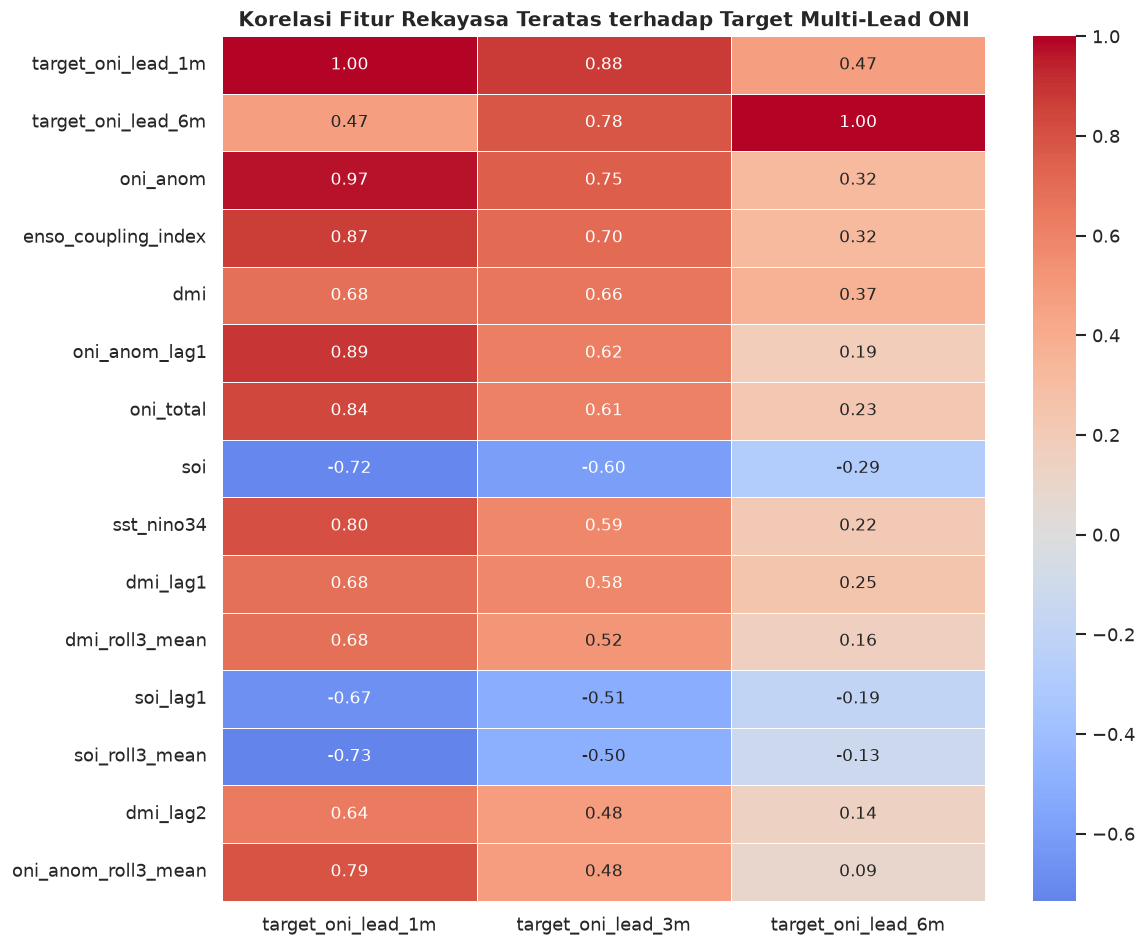

Tersimpan: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\37_feature_target_correlation_matrix.png


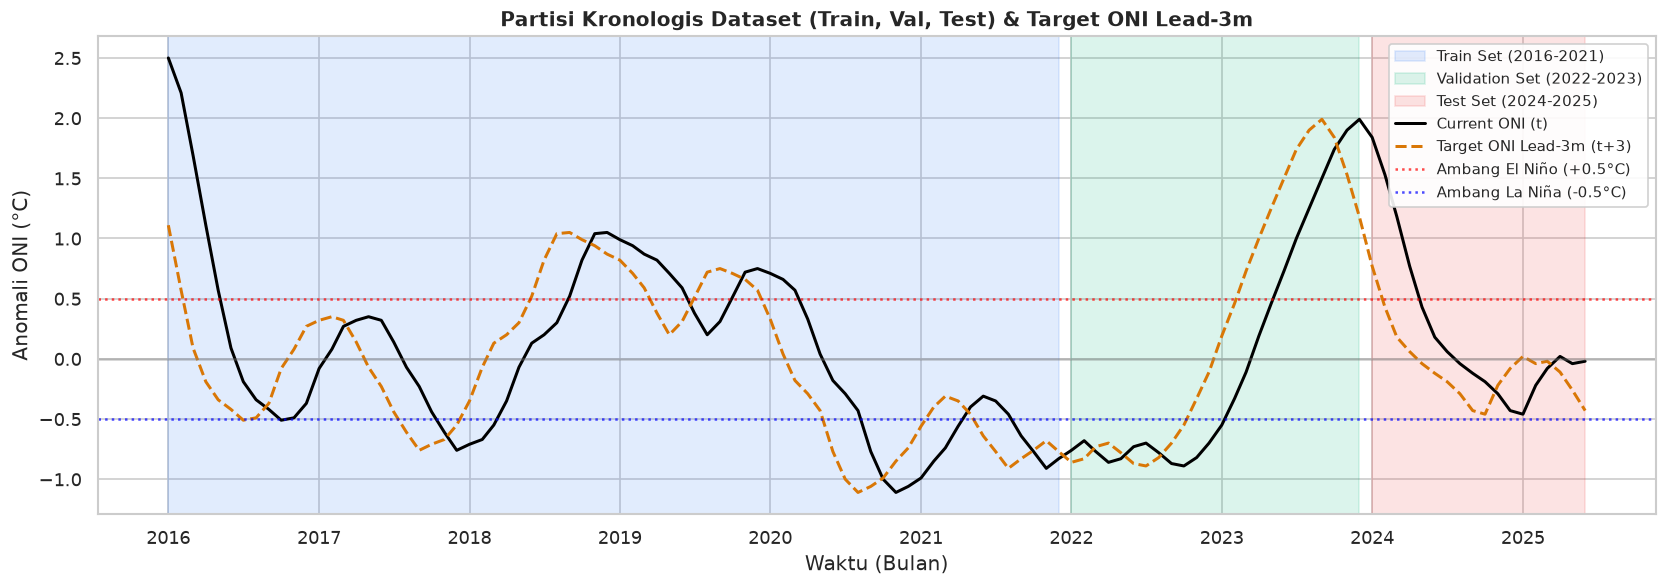

Tersimpan: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\38_chronological_splits_timeline.png


In [7]:
# 1. Korelasi Fitur Teratas dengan Target Regresi
corrs = df_clean[feature_cols + ["target_oni_lead_1m", "target_oni_lead_3m", "target_oni_lead_6m"]].corr()

# Pilih 15 fitur dengan korelasi absolut tertinggi terhadap target_oni_lead_3m
top_features = corrs["target_oni_lead_3m"].abs().sort_values(ascending=False).iloc[1:16].index

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corrs.loc[top_features, ["target_oni_lead_1m", "target_oni_lead_3m", "target_oni_lead_6m"]],
    annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar=True, ax=ax, linewidths=0.5
)
ax.set_title("Korelasi Fitur Rekayasa Teratas terhadap Target Multi-Lead ONI", fontsize=12, fontweight="bold")
plt.tight_layout()
fig_corr_path = FIGURES_DIR / "37_feature_target_correlation_matrix.png"
fig.savefig(fig_corr_path, dpi=300)
plt.show()
print(f"Tersimpan: {fig_corr_path}")

# 2. Timeline Kronologis Train / Val / Test
fig, ax = plt.subplots(figsize=(14, 5))

ax.axvspan(df_clean.index[train_mask][0], df_clean.index[train_mask][-1], color="#3b82f6", alpha=0.15, label="Train Set (2016-2021)")
ax.axvspan(df_clean.index[val_mask][0], df_clean.index[val_mask][-1], color="#10b981", alpha=0.15, label="Validation Set (2022-2023)")
ax.axvspan(df_clean.index[test_mask][0], df_clean.index[test_mask][-1], color="#ef4444", alpha=0.15, label="Test Set (2024-2025)")

ax.plot(df_clean.index, df_clean["oni_anom"], color="black", lw=1.8, label="Current ONI (t)")
ax.plot(df_clean.index, df_clean["target_oni_lead_3m"], color="#d97706", linestyle="--", lw=1.8, label="Target ONI Lead-3m (t+3)")

ax.axhline(0.5, color="red", linestyle=":", alpha=0.7, label="Ambang El Niño (+0.5°C)")
ax.axhline(-0.5, color="blue", linestyle=":", alpha=0.7, label="Ambang La Niña (-0.5°C)")
ax.axhline(0, color="gray", linestyle="-", alpha=0.4)

ax.set_title("Partisi Kronologis Dataset (Train, Val, Test) & Target ONI Lead-3m", fontsize=12, fontweight="bold")
ax.set_xlabel("Waktu (Bulan)")
ax.set_ylabel("Anomali ONI (°C)")
ax.legend(loc="upper right", framealpha=0.9, fontsize=9)
plt.tight_layout()
fig_split_path = FIGURES_DIR / "38_chronological_splits_timeline.png"
fig.savefig(fig_split_path, dpi=300)
plt.show()
print(f"Tersimpan: {fig_split_path}")


## 7. Ekspor Dataset Siap Latih (*Processed Features*)

Dataset disimpan dalam dua format:
1. **Unscaled Master Dataset**: `dataset/features_master_unscaled.csv` (seluruh fitur asli bersama target, berguna untuk analisis pohon/Tree-based model).
2. **Standardized Train/Val/Test Sets**: Disimpan per partisi terstandarisasi untuk model Neural Networks / LSTM / Linear Models.

In [8]:
# 1. Simpan Unscaled Master
master_export_path = DATASET_DIR / "features_master_unscaled.csv"
df_clean.to_csv(master_export_path)
print(f"[OK] Master Dataset disimpan: {master_export_path} ({df_clean.shape})")

# 2. Simpan Scaled Splits bersama Target
train_df = pd.concat([X_train_scaled, y_train], axis=1)
val_df = pd.concat([X_val_scaled, y_val], axis=1)
test_df = pd.concat([X_test_scaled, y_test], axis=1)

train_df.to_csv(DATASET_DIR / "train_features.csv")
val_df.to_csv(DATASET_DIR / "val_features.csv")
test_df.to_csv(DATASET_DIR / "test_features.csv")

print(f"[OK] Train features: {DATASET_DIR / 'train_features.csv'} ({train_df.shape})")
print(f"[OK] Val features  : {DATASET_DIR / 'val_features.csv'} ({val_df.shape})")
print(f"[OK] Test features : {DATASET_DIR / 'test_features.csv'} ({test_df.shape})")

print("\n=== RINGKASAN DATASET PREPROCESSED ===")
print(f"- Fitur Prediktor : {len(feature_cols)} kolom")
print(f"- Variabel Target : {len(target_cols)} kolom")
print(f"- Total Sampel    : {len(df_clean)} bulan (Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)})")


[OK] Master Dataset disimpan: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\dataset\features_master_unscaled.csv ((114, 73))
[OK] Train features: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\dataset\train_features.csv ((72, 73))
[OK] Val features  : C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\dataset\val_features.csv ((24, 73))
[OK] Test features : C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\dataset\test_features.csv ((18, 73))

=== RINGKASAN DATASET PREPROCESSED ===
- Fitur Prediktor : 67 kolom
- Variabel Target : 6 kolom
- Total Sampel    : 114 bulan (Train=72, Val=24, Test=18)
